<a href="https://colab.research.google.com/github/Jucksun/gsp-csice-research/blob/main/practiceBlindDeconv_Expanded.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
%pip install pygsp

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.9/1.9 MB 33.1 MB/s eta 0:00:00


In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pygsp as pg

# Minnesota road network graph N = 2642
G = pg.graphs.Minnesota()
N = G.N

#  Graph Laplacian and U
S = G.L.toarray()
lam, U = np.linalg.eigh(S)

#  signals
M = 2000
rng = np.random.default_rng(42)

#GFT and C_hat_x
rho = 0.25
C_hat_x = (1 - rho) * np.eye(N) + rho * np.ones((N, N))

#  signals in GFT
X_hat = rng.multivariate_normal(np.zeros(N), C_hat_x, size=M).T
X = U @ X_hat

# 4. Define source graph edge connectivity R
std_x = np.sqrt(np.diag(C_hat_x))
rho_x = C_hat_x / np.outer(std_x, std_x)
R_edges = np.abs(rho_x) >= 0.01

In [ ]:
#  channel frequency responses gamma(n) = eps(n) * (1 + u(n))
eps = rng.choice([-1, 1], size=N)
u = rng.uniform(-0.2, 0.2, size=N)
gamma_true = eps * (1 + u)

Gamma = np.diag(gamma_true)
sigma = 0.5

# Y_hat = Gamma @ X_hat + Noise
Y_hat = Gamma @ X_hat + sigma * rng.standard_normal((N, M))
Y_obs = U @ Y_hat

#covariance matrix of observations C_hat_y_M
C_hat_y_M = (Y_hat @ Y_hat.T) / M

In [ ]:
#Eq. III.10
gamma_abs = np.zeros(N)
for n in range(N):
    neighbors = [
        np_idx for np_idx in range(N) if R_edges[n, np_idx] and np_idx != n
    ]
    if len(neighbors) == 0:
        continue

    sum_val = 0.0
    for np_idx in neighbors:
        alpha = C_hat_y_M[n, n] - C_hat_y_M[np_idx, np_idx]
        beta = C_hat_y_M[n, np_idx] / C_hat_x[n, np_idx]
        mu = 4 * C_hat_x[n, n] * C_hat_x[np_idx, np_idx] * (beta**2) + (
            alpha**2
        )

        gamma_sq = (np.sqrt(mu) + alpha) / (2 * C_hat_x[n, n])
        sum_val += np.sqrt(max(gamma_sq, 0))

    gamma_abs[n] = sum_val / len(neighbors)

#Sign Propagation via Anchor Node (n=0)
gamma_sign = np.ones(N)
for n in range(1, N):
    beta_n0 = C_hat_y_M[n, 0] / C_hat_x[n, 0]
    gamma_sign[n] = gamma_sign[0] * np.sign(beta_n0)

gamma_est = gamma_abs * gamma_sign

# Fix global sign
if np.dot(gamma_est, gamma_true) < 0:
    gamma_est = -gamma_est

<>:18: SyntaxWarning: invalid escape sequence '\g'
<>:19: SyntaxWarning: invalid escape sequence '\g'
<>:18: SyntaxWarning: invalid escape sequence '\g'
<>:19: SyntaxWarning: invalid escape sequence '\g'
/tmp/ipykernel_16122/4049661199.py:18: SyntaxWarning: invalid escape sequence '\g'
  plt.plot(gamma_true[:100], "o-", label="True $\gamma(n)$")
/tmp/ipykernel_16122/4049661199.py:19: SyntaxWarning: invalid escape sequence '\g'
  plt.plot(gamma_est[:100], "s--", label="Estimated $\gamma_M(n)$ (CSICE)")


Minnesota Road Network (N=2642 nodes)
Channel Estimation Relative Error: 0.0293


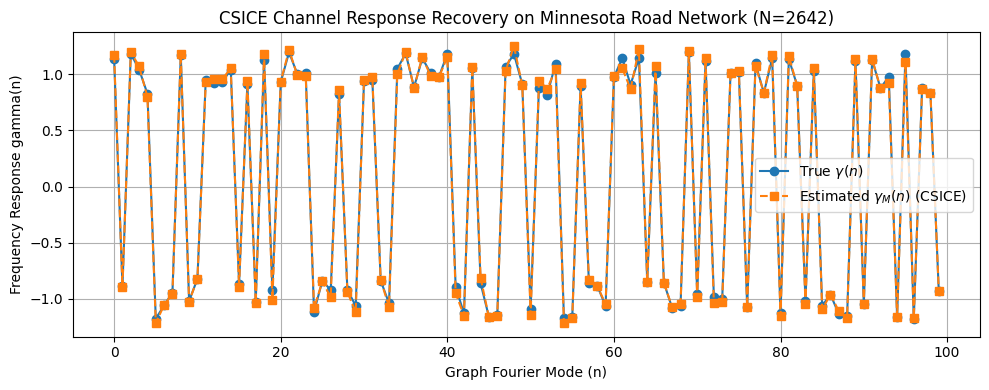

In [ ]:
# Pseudo-inverse filtering to reconstruct GFT signals
Gamma_M_inv = np.diag(1.0 / gamma_est)
X_tilde_hat = Gamma_M_inv @ Y_hat
X_tilde = U @ X_tilde_hat

# Calculate empirical covariance of reconstructed signals
C_hat_xtilde_M = (X_tilde_hat @ X_tilde_hat.T) / M

# Relative channel estimation error
gamma_error = np.linalg.norm(gamma_est - gamma_true) / np.linalg.norm(
    gamma_true
)
print(f"Minnesota Road Network (N={N} nodes)")
print(f"Channel Estimation Relative Error: {gamma_error:.4f}")

# Plot True vs Estimated Channel Responses (first 100 modes)
plt.figure(figsize=(10, 4))
plt.plot(gamma_true[:100], "o-", label="True $\gamma(n)$")
plt.plot(gamma_est[:100], "s--", label="Estimated $\gamma_M(n)$ (CSICE)")
plt.title(
    f"CSICE Channel Response Recovery on Minnesota Road Network (N={N})"
)
plt.xlabel("Graph Fourier Mode (n)")
plt.ylabel("Frequency Response gamma(n)")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()